# 04. Rete LSTM, scelta del modello finale e test

**Progetto:** HelpDesk AI · **Passo 2:** modelli

Il miglior modello finora è la **SVM lineare con bigrammi**: F1 macro **0,8554** (versione calibrata) sulla validation. Come TF-IDF, la SVM vede ogni ticket come una "borsa di parole": conta quali parole (e coppie di parole) compaiono, ma non il loro ordine.

Una **rete LSTM** invece **legge le parole in sequenza**, una dopo l'altra, e tiene una "memoria" di quello che ha letto. La domanda di questo notebook è:

**L'ordine delle parole aggiunge informazione utile, abbastanza da giustificare un modello più complesso?**

Dopo aver risposto a questa domanda: 

1. scegliamo il **modello finale** confrontando LSTM e SVM;
2. lo valutiamo **una sola volta sul test**, che finora non abbiamo mai toccato;
3. scegliamo la **soglia di sicurezza** sotto la quale il chatbot chiederà più dettagli;
4. salviamo tutto ciò che servirà all'applicazione.

### Cosa faremo:
1. Import e configurazione
2. Caricamento dei dati e validazione interna
3. Dal testo ai numeri: vocabolario e sequenze
4. L'architettura della rete
5. Addestramento
6. Le curve di apprendimento
7. LSTM contro SVM sulla validation
8. Scelta del modello finale
9. Valutazione sul test
10. Soglia di sicurezza
11. Salvataggio
12. Riepilogo

## 1. Import e configurazione
Le reti neurali partono da pesi casuali e, senza precauzioni, ogni addestramento può dare risultati un po' diversi. Per avere risultati riproducibili:
- `TF_ENABLE_ONEDNN_OPTS=0` disattiva le ottimizzazioni Intel (oneDNN) che, come avverte anche il messaggio che compare all'importazione di TensorFlow, possono cambiare le ultime cifre dei calcoli;
- `keras.utils.set_random_seed` fissa il seme di Python, NumPy e TensorFlow insieme;
- `enable_op_determinism` chiede a TensorFlow di eseguire le operazioni sempre nello stesso ordine.

Le variabili vanno impostate prima di importare TensoFlow

- `TF_CPP_MIN_LOG_LEVEL=2` nasconde i messaggi informativi di TensorFlow.

In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path
from collections import Counter
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

print("TensorFlow", tf.__version__, "Keras", keras.__version__)

TensorFlow 2.21.0 Keras 3.15.1


In [2]:
# --- Riproducibilità ---
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()

# --- Percorsi ---
PROJECT_DIR = Path("..")
SPLIT_PATH = PROJECT_DIR / "data" / "processed" / "tickets_split.csv"
MODELS_DIR = PROJECT_DIR / "models"

# --- Colonne ---
TEXT_COL = "Document"
LABEL_COL = "Topic_group"

# --- Stile dei grafici ---
COLORE = "#2a78d6"            # train / serie principale
COLORE_2 = "#eb6834"          # validazione / seconda serie
TESTO_SECONDARIO = "#52514e"
GRIGLIA = "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIGLIA,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRIGLIA,
    "xtick.color": TESTO_SECONDARIO,
    "ytick.color": TESTO_SECONDARIO,
})
pd.set_option("display.max_colwidth", 200)

## 2. Caricamento dei dati e validazione interna
Una rete neurale si addestra in epoche: ad ogni epoca vede tutto il train una volta. Con troppe epoche inizia ad imparare a memoria il train (*overfitting*). Per capire quando fermarsi usiamo l'**early stopping**: dopo ogni epoca misuriamo l'errore sui dati che la rete non usa per addestrarsi e ci fermiamo quando smette di migliorare.

Se per questo usassimo la validation, il confronto con la SVM non sarebbe più alla pari e quindi ricaviamo una validazione interna dal train (10%, divisa per gruppi).

Il prezzo è che la LSTM si addestra sul 90% del train mentre la SVM sul 100% ma l'alternativa sarebbe di riaddestrare la LSTM su tutto il train con il numero di epoche trovato raddoppiando però i tempi.

In [3]:
df = pd.read_csv(SPLIT_PATH)

with open(MODELS_DIR / "liste_parole.json", encoding="utf-8") as f:
    RUMORE_EMAIL = set(json.load(f)["rumore_email"])

def pulisci(testo):
    # Toglie le parole del "rumore_email"
    return " ".join(parola for parola in str(testo).split() if parola not in RUMORE_EMAIL)

df["testo_pulito"] = df[TEXT_COL].map(pulisci)

CLASSI = sorted(df[LABEL_COL].unique()) # ordine alfabetico come scikit-learn
indice_classe = {c: i for i, c in enumerate(CLASSI)}
df["etichette"] = df[LABEL_COL].map(indice_classe) # la rete vuole numeri, non nomi

print("Categorie: ", CLASSI)

Categorie:  ['Access', 'Administrative rights', 'HR Support', 'Hardware', 'Internal Project', 'Miscellaneous', 'Purchase', 'Storage']


In [4]:
def scegli_divisione_bilanciata(dati, n_splits):
    # Stessa funzione del notebook 02: tra le divisioni possibili sceglie quella con le proporzioni di categorie più vicine al totale
    divisore = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    proporzioni_totali = dati[LABEL_COL].value_counts(normalize=True)
    migliore, scarto_minimo = None, np.inf
    for idx_grande, idx_piccolo in divisore.split(dati, dati[LABEL_COL], groups=dati["gruppo"]):
        proporzioni = dati[LABEL_COL].iloc[idx_piccolo].value_counts(normalize=True)
        scarto = (proporzioni.reindex(proporzioni_totali.index, fill_value=0) - proporzioni_totali).abs().max()
        if scarto < scarto_minimo:
            migliore, scarto_minimo = (idx_grande, idx_piccolo), scarto
    return migliore, scarto_minimo    

train_completo = df[df["split"] == "train"]
(idx_tr, idx_vi), scarto = scegli_divisione_bilanciata(train_completo, n_splits=10)
train_lstm = train_completo.iloc[idx_tr]
val_interna = train_completo.iloc[idx_vi]
val = df[df["split"] == "val"]
test = df[df["split"] == "test"]

print(f"Train LSTM: {len(train_lstm)} | Validazione interna: {len(val_interna)}"
      f" (scarto max {scarto * 100:.1f} punti) | Validation: {len(val)} | Test: {len(test)}")

Train LSTM: 34572 | Validazione interna: 3787 (scarto max 1.2 punti) | Validation: 4739 | Test: 4739


## 3. Dal testo ai numeri: vocabolario e sequenza
Una rete neurale lavora con i numeri. Il layer TextVectorization di Keras:
1. costruisce un vocabolario del train, assegnando a ogni parola un numero intero;
2. trasforma ogni ticket in una sequenza di numeri, una per parola, nell'ordine originale;
3. rende tutte le sequenze lunghe uguali: le più corte vengono completate con zeri e le più lunghe vengono tagliate.

#### Le scelte da fare:
- Dimensione del vocabolario: Teniamo le parole presenti almeno 2 volte nel train (equivalente del min_df usato con TF-IDF). Le parole rarissime diventano un unico simbolo ([UNK]) così la rete non spreca parametri su parole viste una sola volta.
- Lunghezza delle sequenze: Nel notebook 01 abbiamo visto che il 95° percentile era 136 parole. Lo ricalcoliamo sui testi senza rumore email e lo arrotondiamo alla decina superiore (95% dei ticket entra per intero mentre il 5% più lungo viene tagliato alla fine). Si potrebbe anche usare la lunghezza massima (981 parole) ma renderebbe l'addestramento molto più lento.

In [5]:
# --- Vocabolario ---
frequenze = Counter(parola for t in train_lstm["testo_pulito"] for parola in t.split())
n_parole_utili = sum(1 for conteggio in frequenze.values() if conteggio >= 2)
MAX_TOKENS = n_parole_utili + 2

# --- Lunghezza ---
lunghezze = train_lstm["testo_pulito"].str.split().str.len()
MAX_LEN = int(np.ceil(lunghezze.quantile(0.95) / 10) * 10)

print(f"Parole diverse nel train: {len(frequenze)} | Presenti almeno 2 volte: {n_parole_utili}")
print(f"MAX_TOKENS = {MAX_TOKENS} | MAX_LEN = {MAX_LEN} parole")
print(f"Ticket tagliati: {(lunghezze > MAX_LEN).mean() * 100:.1f}%")

Parole diverse nel train: 11114 | Presenti almeno 2 volte: 8573
MAX_TOKENS = 8575 | MAX_LEN = 120 parole
Ticket tagliati: 4.4%


In [6]:
vettorizzatore = layers.TextVectorization(
    max_tokens = MAX_TOKENS,
    output_mode = "int",
    output_sequence_length = MAX_LEN,
)
vettorizzatore.adapt(train_lstm["testo_pulito"].to_numpy())

def in_sequenze(dati):
    return vettorizzatore(dati["testo_pulito"].to_numpy())

X_tr, y_tr = in_sequenze(train_lstm), train_lstm["etichette"].to_numpy()
X_vi, y_vi = in_sequenze(val_interna), val_interna["etichette"].to_numpy()
X_val, y_val = in_sequenze(val), val["etichette"].to_numpy()

vocabolario = vettorizzatore.get_vocabulary()
print("Dimensioni di X_tr: ", X_tr.shape)
print("Prime 10 voci del vocabolario: ", [str(parola) for parola in vocabolario[:10]])

# Esempio ticket e sua sequenza
print("\nTesto: ", train_lstm["testo_pulito"].iloc[0][:120])
print("Sequenza ", X_tr[0][:20].numpy(), "...")

Dimensioni di X_tr:  (34572, 120)
Prime 10 voci del vocabolario:  ['', '[UNK]', 'for', 'you', 'access', 'help', 'with', 'can', 'by', 'have']

Testo:  connection with icon icon setup icon per icon engineers let other details needed lead
Sequenza  [ 265    6 1328 1328  172 1328  187 1328 1693   24   61   28   62  112
    0    0    0    0    0    0] ...


### Osservazioni (parte 3)
- **11.114** parole diverse nel train, **8.573** presenti almeno 2 volte (il 23% compare una sola volta e diventa [UNK]): **MAX_TOKENS = 8.575** (+ padding e [UNK]) · **MAX_LEN = 120** parole (95° percentile dei testi senza rumore email, più corti dei 136 del notebook 01) · ticket tagliati: **4,4%**.

## 4. L'architettura della rete
```
testo -> [Embedding] -> [LSTM bidirezionale] -> [Dropout] -> [Dense softmax] -> 8 probabilità
```
| Layer | Cosa fa | Perché |
|---|---|---|
| **Embedding** (128 dimensioni) | trasforma ogni numero di parola in un vettore di 128 valori, imparato durante l'addestramento | parole con significato simile finiscono per avere vettori simili: la rete impara che *laptop* e *notebook* sono vicini, cosa che TF-IDF non può fare |
| `mask_zero=True` | segnala alla rete quali posizioni sono padding | così gli zeri aggiunti non vengono "letti" come parole |
| **LSTM** (64 unità) | legge la sequenza parola per parola, con una memoria regolata da "porte" (*gate*) che decidono cosa ricordare e cosa dimenticare | coglie il contesto: *card* dopo *time* è diverso da *card* dopo *access* |
| **Bidirectional** | due LSTM, una legge da sinistra a destra, l'altra da destra a sinistra | ogni parola viene interpretata conoscendo sia ciò che viene prima sia ciò che viene dopo |
| **Dropout** (30%) | durante l'addestramento "spegne" a caso il 30% dei valori | riduce l'overfitting |
| **Dense softmax** (8 unità) | una probabilità per categoria, con somma 1 | le probabilità servono alla soglia di sicurezza: a differenza della SVM, qui sono native |

128 dimensioni di embedding e 64 unità LSTM sono valori comuni per dataset di queste dimensioni: abbastanza per catturare le differenze tra 8 categorie, non tanti da rendere l'addestramento lento su CPU.

In [7]:
N_CLASSI = len(CLASSI)

modello_lstm = keras.Sequential([
    keras.Input(shape=(MAX_LEN,), dtype="int64"),
    layers.Embedding(input_dim=MAX_TOKENS, output_dim=128, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.3),
    layers.Dense(N_CLASSI, activation="softmax"),
], name="lstm_ticket")

modello_lstm.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
modello_lstm.summary()

Model: "lstm_ticket"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 120, 128)       │     1,097,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,197,448 (4.57 MB)

 Trainable params: 1,197,448 (4.57 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Addestramento
| Impostazione | Valore | Perché |
|---|---|---|
| `class_weight` | pesi bilanciati | come per SVM e regressione logistica: gli errori sulle categorie piccole pesano di più |
| `batch_size` | 128 | quanti ticket la rete vede prima di aggiornare i pesi: compromesso tra velocità su CPU e stabilità |
| `epochs` | massimo 15 | un tetto: in pratica si ferma prima, grazie all'early stopping |
| `EarlyStopping` | ferma se l'errore sulla validazione interna non migliora per 2 epoche, e ripristina i pesi dell'epoca migliore | evita l'overfitting e non spreca tempo |

**Ottimizzatore Adam** con `learning_rate=1e-3`: è il valore predefinito e il punto di partenza più comune. Adam adatta automaticamente il passo per ogni peso.

In [8]:
pesi = compute_class_weight("balanced", classes=np.arange(N_CLASSI), y=y_tr)
pesi_classi = dict(enumerate(pesi))
print("Pesi delle classi: ", {CLASSI[i]: round(float(p), 2) for i, p in pesi_classi.items()})

arresto_anticipato = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
)

Pesi delle classi:  {'Access': 0.84, 'Administrative rights': 3.41, 'HR Support': 0.55, 'Hardware': 0.44, 'Internal Project': 2.83, 'Miscellaneous': 0.85, 'Purchase': 2.27, 'Storage': 2.16}


In [9]:
%%time
storia = modello_lstm.fit(
    X_tr, y_tr,
    validation_data = (X_vi, y_vi),
    epochs = 15,
    batch_size = 128,
    class_weight = pesi_classi,
    callbacks = [arresto_anticipato],
    verbose = 1
)

Epoch 1/15
271/271 ━━━━━━━━━━━━━━━━━━━━ 64s 229ms/step - accuracy: 0.7179 - loss: 0.8030 - val_accuracy: 0.8249 - val_loss: 0.5369
Epoch 2/15
271/271 ━━━━━━━━━━━━━━━━━━━━ 65s 241ms/step - accuracy: 0.8618 - loss: 0.3175 - val_accuracy: 0.8339 - val_loss: 0.4976
Epoch 3/15
271/271 ━━━━━━━━━━━━━━━━━━━━ 65s 241ms/step - accuracy: 0.8925 - loss: 0.2345 - val_accuracy: 0.8297 - val_loss: 0.5019
Epoch 4/15
271/271 ━━━━━━━━━━━━━━━━━━━━ 84s 310ms/step - accuracy: 0.9079 - loss: 0.1897 - val_accuracy: 0.8260 - val_loss: 0.5409
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
CPU times: total: 32min 23s
Wall time: 4min 38s


## 6. Le curve di apprendimento

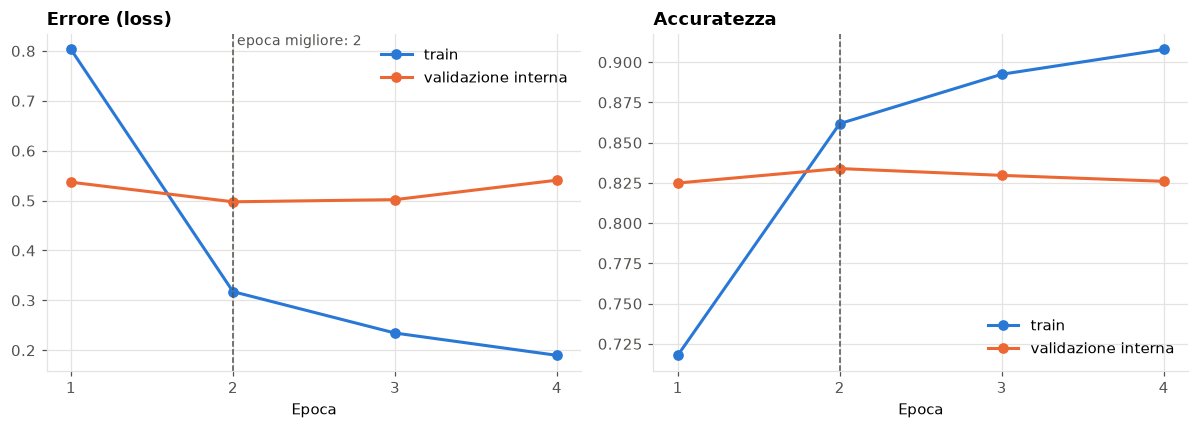

,accuracy,loss,val_accuracy,val_loss
1,0.7179,0.8030,0.8249,0.5369
2,0.8618,0.3175,0.8339,0.4976
3,0.8925,0.2345,0.8297,0.5019
4,0.9079,0.1897,0.8260,0.5409


In [10]:
storico = pd.DataFrame(storia.history)
storico.index = storico.index + 1
epoca_migliore = int(storico["val_loss"].idxmin())

fig, assi = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica, titolo in [(assi[0], "loss", "Errore (loss)"), (assi[1], "accuracy", "Accuratezza")]:
    ax.plot(storico.index, storico[metrica], marker="o", color=COLORE, linewidth=2, label="train")
    ax.plot(storico.index, storico[f"val_{metrica}"], marker="o", color=COLORE_2, linewidth=2, label="validazione interna")
    ax.axvline(epoca_migliore, color=TESTO_SECONDARIO, linestyle="--", linewidth=1)
    ax.set_title(titolo)
    ax.set_xlabel("Epoca")
    ax.set_xticks(storico.index)
    ax.legend(frameon=False)
assi[0].text(epoca_migliore, assi[0].get_ylim()[1], f" epoca migliore: {epoca_migliore}", va="top", fontsize=9, color=TESTO_SECONDARIO)
plt.tight_layout()
plt.show()

display(storico.round(4))

### Osservazioni (parti 5-6)
- Addestramento su CPU fermato dall'early stopping all'epoca 4, pesi ripristinati dall'epoca 2 (loss validazione interna 0,498, accuratezza 83,4%).
- **Overfitting rapido**: il train continua a migliorare (accuratezza 71,8% -> 90,8%, loss 0,80 -> 0,19), mentre la validazione interna resta intorno all'83% e la sua loss risale dopo l'epoca 2.
- Causa probabile: 1.197.448 parametri (1.097.600 nell'Embedding, imparato da zero) per 34.572 ticket, più il rumore nelle etichette, che la rete memorizza nel train.

## 7. LSTM contro SVM sulla validation

In [11]:
modello_svm = joblib.load(MODELS_DIR / "modello_classico_migliore.joblib")

# --- LSTM --- 
inizio = time.perf_counter()
prob_lstm_val = modello_lstm.predict(X_val, verbose=0)
tempo_lstm = time.perf_counter() - inizio
pred_lstm_val = np.array(CLASSI)[prob_lstm_val.argmax(axis=1)]

# --- SVM ---
inizio = time.perf_counter()
prob_svm_val = modello_svm.predict_proba(val[TEXT_COL])
tempo_svm = time.perf_counter() - inizio
pred_svm_val = modello_svm.classes_[prob_svm_val.argmax(axis=1)]

y_val_nomi = val[LABEL_COL].to_numpy()
f1_lstm = f1_score(y_val_nomi, pred_lstm_val, average="macro")
f1_svm = f1_score(y_val_nomi, pred_svm_val, average="macro")

# Dimensione dei modelli: salviamo temporaneamente LSTM per misurarla
modello_lstm.save(MODELS_DIR / "lstm_temporaneo.keras")
dimensione_lstm = (MODELS_DIR / "lstm_temporaneo.keras").stat().st_size / 1e6
dimensione_svm = (MODELS_DIR / "modello_classico_migliore.joblib").stat().st_size / 1e6
(MODELS_DIR / "lstm_temporaneo.keras").unlink()

confronto = pd.DataFrame({
    "F1 macro": [f1_svm, f1_lstm],
    "accuratezza": [accuracy_score(y_val_nomi, pred_svm_val), accuracy_score(y_val_nomi, pred_lstm_val)],
    "tempo previsione (ms per ticket)": [tempo_svm / len(val) * 1000, tempo_lstm / len(val) * 1000],
    "dimensione (MB)": [dimensione_svm, dimensione_lstm],
}, index=["SVM lineare (bigrammi, calibrata)", "LSTM bidirezionale"]).round(4)
display(confronto)

,F1 macro,accuratezza,tempo previsione (ms per ticket),dimensione (MB)
"SVM lineare (bigrammi, calibrata)",0.8554,0.8557,0.0391,14.1451
LSTM bidirezionale,0.8348,0.8327,0.4628,14.4105


In [12]:
f1_per_categoria = pd.DataFrame({
    "SVM": f1_score(y_val_nomi, pred_svm_val, average=None, labels=CLASSI),
    "LSTM": f1_score(y_val_nomi, pred_lstm_val, average=None, labels=CLASSI),
}, index=CLASSI)
f1_per_categoria["differenza (LSTM - SVM)"] = f1_per_categoria["LSTM"] - f1_per_categoria["SVM"]
display(f1_per_categoria.sort_values("differenza (LSTM - SVM)", ascending=False).round(3))

# I due ticket più "difficili" dei notebook precedenti
casi = val[val[TEXT_COL].str.contains("time card approval|installation the memories", regex=True)]
if len(casi):
    tabella_casi = casi[[TEXT_COL, LABEL_COL]].copy()
    tabella_casi[TEXT_COL] = tabella_casi[TEXT_COL].str.slice(0, 60)
    tabella_casi["SVM"] = modello_svm.predict(casi[TEXT_COL])
    tabella_casi["LSTM"] = np.array(CLASSI)[modello_lstm.predict(in_sequenze(casi), verbose=0).argmax(axis=1)]
    display(tabella_casi)

,SVM,LSTM,differenza (LSTM - SVM)
Purchase,0.865,0.870,0.005
Internal Project,0.860,0.853,-0.007
HR Support,0.854,0.839,-0.015
Miscellaneous,0.828,0.812,-0.015
Access,0.901,0.879,-0.021
Storage,0.904,0.878,-0.026
Hardware,0.846,0.808,-0.038
Administrative rights,0.786,0.738,-0.048


,Document,Topic_group,SVM,LSTM
13064,installation the memories friday pm upgrade has assigned hi,Hardware,Miscellaneous,Administrative rights
14791,time card approval tuesday pm card issue importance high hi,HR Support,Access,Access


### Osservazioni (parte 7)
| Modello | F1 macro | Accuratezza | Dimensione |
|---|---|---|---|
| SVM lineare (bigrammi, calibrata) | **0,8554** | **0,8557** | 14,1 MB |
| LSTM bidirezionale | 0,8348 | 0,8327 | 14,4 MB |

**Risultato complessivo**
- La SVM supera la LSTM di **2,1 punti** di F1 macro, quasi cinque volte la deviazione standard della SVM in cross-validation (0,0043): la differenza è reale.
- Motivi principali:
  - il compito dipende soprattutto da parole chiave, già catturate da TF-IDF con bigrammi;
  - il preprocessing del dataset ha rimosso molte parole e perfino negazioni, indebolendo l'informazione sull'ordine, che è il punto di forza della LSTM;
  - la LSTM ha 1,2 milioni di parametri da imparare da zero su 34.572 ticket (overfitting dopo l'epoca 2);
  - un modello con tanta capacità memorizza le etichette sbagliate;
  - la LSTM si addestra sul 10% di dati in meno.

**Per categoria**
- La LSTM è peggiore in 7 categorie su 8. Fa leggermente meglio solo in Purchase.

**Ticket difficili**
- Restano sbagliati per entrambi i modelli: "time card approval" -> Access; "installation the memories" -> Miscellaneous (SVM) e Administrative rights (LSTM). Servirebbero più esempi nei dati, non un modello diverso.

**Aspetti pratici**
- La LSTM è molto più lenta ma entrambi i modelli sono istantanei per un chatbot.
- File di dimensioni simili (la LSTM salva anche lo stato dell'ottimizzatore Adam; la SVM calibrata contiene 5 modelli e un vocabolario con i bigrammi). La differenza vera è la dipendenza da TensorFlow nell'app pubblicata.

**Conclusione**
- Non ottimizzo ulteriormente la LSTM: per essere scelta dovrebbe guadagnare di più (circa 3 punti).

## 8. Scelta del modello finale
Il modello finale non lo scegliamo solo con l'F1. Per un'applicazione contano anche altri aspetti come:
| Criterio | Perché conta per HelpDesk AI |
|---|---|
| **F1 macro** | la qualità della classificazione |
| **Velocità** | il chatbot deve rispondere subito |
| **Dimensione e dipendenze** | la LSTM richiede TensorFlow (centinaia di MB) anche nell'app pubblicata; la SVM solo scikit-learn. Sui servizi di deploy gratuiti risorse e memoria sono limitate |
| **Interpretabilità** | della SVM possiamo leggere i pesi delle parole; la LSTM è più difficile da spiegare |
| **Probabilità** | entrambe le forniscono (la SVM grazie alla calibrazione) |

### Su cosa basiamo la scelta?
Scegliamo la LSTM solo se migliora l'F1 macro di almeno 0,01, cioè circa due deviazioni standard della cross-validation della SVM (0,0043). Sotto quella soglia la differenza non è abbastanza sicura da giustificare un modello più pesante e meno interpretabile.

In [13]:
DIFFERENZA_MINIMA = 0.01
differenza = f1_lstm - f1_svm

MODELLO_FINALE = "LSTM" if differenza >= DIFFERENZA_MINIMA else "SVM"
print(f"F1 macro: SVM {f1_svm:.4f} | LSTM {f1_lstm:.4f} | Differenza {differenza:+.4f}")
print(f"Modello finale: {MODELLO_FINALE}")

F1 macro: SVM 0.8554 | LSTM 0.8348 | Differenza -0.0205
Modello finale: SVM


In [14]:
def predici(testi_originali):
    # Restituisce (categorie previste, probabilità) con il modello finale. Riceve il testo originale: la pulizia viene eseguita dalla funzione stessa
    if MODELLO_FINALE == "SVM":
        probabilita = modello_svm.predict_proba(testi_originali)
        classi = modello_svm.classes_
    else:
        puliti = pd.DataFrame({"testo_pulito": pd.Series(testi_originali).map(pulisci)})
        probabilita = modello_lstm.predict(in_sequenze(puliti), verbose=0)
        classi = np.array(CLASSI)
    return classi[probabilita.argmax(axis=1)], probabilita

### Osservazioni (parte 8)
- La regola, fissata prima del test per evitare condizionamenti, sceglie la **SVM**: la LSTM non solo non supera la soglia di +0,01, ma è più bassa di 0,0205. Con un margine così netto la scelta non dipende dal valore della soglia: vincerebbe la SVM anche con `DIFFERENZA_MINIMA = 0`.
- Gli altri criteri vanno nella stessa direzione: la SVM è più veloce per ticket, nell'app pubblicata richiede solo scikit-learn (niente TensorFlow), è interpretabile (pesi delle parole) e fornisce probabilità calibrate. Dimensione dei file simile (circa 14 MB).
- La LSTM fa meglio solo in Purchase (+0,005, differenza trascurabile): non c'è una categoria in cui valga la pena usarla.
- Il codice delle sezioni successive (previsione, soglia, salvataggio) segue `MODELLO_FINALE` invece di dare per scontata la SVM: se il dataset cambiasse e la regola scegliesse la LSTM, il notebook funzionerebbe senza modifiche e salverebbe il modello giusto, compreso il vocabolario.

## 9. Valutazione sul test
Il test contiene 4.739 ticket che nessuna scelta ha mai visto fino ad ora: né la pulizia, né i modelli, né i parametri e neppure la scelta del modello finale.
Lo usiamo una sola volta e, qualunque risultato esca, non torniamo indietro a cambiare il modello per migliorarlo, altrimenti il test diventerebbe un'altra validation.

Ci aspettiamo un F1 macro vicino a quello della validation: una differenza di qualche millesimo è normale mentre una grande indicherebbe che le nostre scelte si sono adattate alla validation.

In [15]:
pred_test, prob_test = predici(test[TEXT_COL])
y_test_nomi = test[LABEL_COL].to_numpy()

f1_test = f1_score(y_test_nomi, pred_test, average="macro")
accuratezza_test = accuracy_score(y_test_nomi, pred_test)
f1_val_finale = f1_svm if MODELLO_FINALE == "SVM" else f1_lstm

print(f"Modello finale: {MODELLO_FINALE}")
print(f"F1 macro | validation {f1_val_finale:.4f} -> test {f1_test:.4f}")
print(f"Accuratezza sul test: {accuratezza_test:.4f}\n")
print(classification_report(y_test_nomi, pred_test, digits=3))

Modello finale: SVM
F1 macro | validation 0.8554 -> test 0.8633
Accuratezza sul test: 0.8601

                       precision    recall  f1-score   support

               Access      0.917     0.888     0.902       713
Administrative rights      0.845     0.710     0.772       176
           HR Support      0.884     0.850     0.866      1091
             Hardware      0.804     0.889     0.844      1362
     Internal Project      0.896     0.854     0.874       212
        Miscellaneous      0.825     0.813     0.819       706
             Purchase      0.945     0.847     0.893       202
              Storage      0.955     0.917     0.936       277

             accuracy                          0.860      4739
            macro avg      0.884     0.846     0.863      4739
         weighted avg      0.863     0.860     0.860      4739



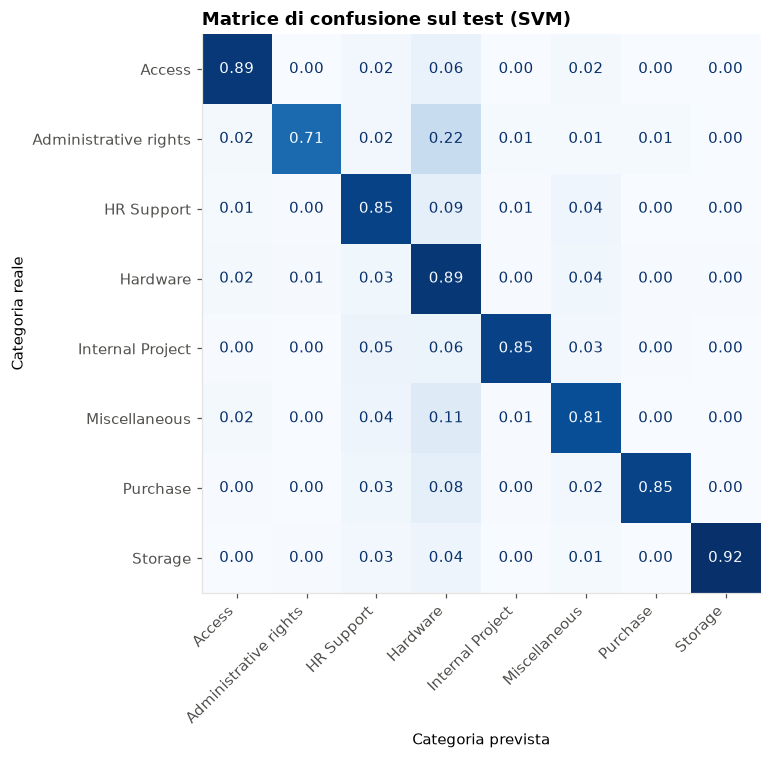

In [16]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test_nomi, pred_test, labels=CLASSI, normalize="true", values_format=".2f", cmap="Blues", xticks_rotation=45, colorbar=False, ax=ax
)
ax.set_title(f"Matrice di confusione sul test ({MODELLO_FINALE})")
ax.set_xlabel("Categoria prevista")
ax.set_ylabel("Categoria reale")
ax.grid(False)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()

### Controllo: effetto della calibrazione (validation)

In [17]:
# Controllo sulla validation (non sul test): la SVM calibrata ha già lo stesso squilibrio tra precision e recall? Se sì, è un effetto della calibrazione e non del test.
print(classification_report(y_val_nomi, pred_svm_val, digits=3))

                       precision    recall  f1-score   support

               Access      0.912     0.889     0.901       713
Administrative rights      0.825     0.750     0.786       176
           HR Support      0.856     0.852     0.854      1092
             Hardware      0.812     0.882     0.846      1361
     Internal Project      0.897     0.825     0.860       212
        Miscellaneous      0.840     0.816     0.828       706
             Purchase      0.908     0.827     0.865       202
              Storage      0.941     0.870     0.904       277

             accuracy                          0.856      4739
            macro avg      0.874     0.839     0.855      4739
         weighted avg      0.857     0.856     0.856      4739



### Osservazioni (parte 9)
- **F1 macro sul test 0,8633** (accuratezza 0,8601) contro 0,8554 sulla validation (+0,008). È la stima più affidabile delle prestazioni su ticket nuovi: il test non è stato usato per nessuna scelta. Il test non è più basso della validation, quindi le scelte non si sono adattate alla validation; la differenza rientra nella variabilità normale tra insiemi di circa 4.700 ticket.
- **F1 per categoria (validation -> test)**: l'ordine dalla migliore alla peggiore è identico in entrambi i casi.

| Categoria | Validation | Test | Differenza |
|---|---|---|---|
| Storage | 0,904 | 0,936 | +0,032 |
| Access | 0,901 | 0,902 | +0,001 |
| Purchase | 0,865 | 0,893 | +0,028 |
| Internal Project | 0,860 | 0,874 | +0,014 |
| HR Support | 0,854 | 0,866 | +0,012 |
| Hardware | 0,846 | 0,844 | −0,002 |
| Miscellaneous | 0,828 | 0,819 | −0,009 |
| Administrative rights | 0,786 | 0,772 | −0,014 |

- Le variazioni più grandi sono nelle categorie piccole (Storage 277 ticket, Purchase 202): pochi ticket spostano molto l'F1. Le categorie grandi (Access, Hardware, Miscellaneous) restano entro 0,01.
- **Confusioni:** il modello ha un difetto principale, quando è incerto risponde Hardware. La colonna Hardware raccoglie gran parte degli errori di tutte le categorie (Administrative rights 22%, Miscellaneous 11%, HR Support 9%, Purchase 8%); fuori da Hardware le confusioni non superano il 5%.
- **Effetto della calibrazione (verificato sulla validation, senza toccare il test):** rispetto alla SVM non calibrata del notebook 03, l'F1 macro resta 0,855 ma cambia il tipo di errore. Precision macro 0,848 -> 0,874, recall macro 0,864 -> 0,839; Hardware recall 0,845 -> 0,882 e precision 0,851 -> 0,812; le categorie piccole diventano più precise ma meno complete (Administrative rights: precision 0,735 -> 0,825, recall 0,790 -> 0,750). La calibrazione trasforma i punteggi in probabilità che rispecchiano la frequenza delle categorie nel train, e così annulla in parte l'effetto di `class_weight="balanced"`. Sul test lo schema è lo stesso (precision macro 0,884, recall macro 0,846): è una proprietà del modello, non del test.
- **Conseguenze per l'app:** il team Hardware riceverebbe parte dei ticket incerti degli altri reparti. La soglia di sicurezza e la riclassificazione sull'intera conversazione prima dell'inoltro serviranno proprio a ridurre questo.

## 10. Soglia di sicurezza
Nell'app, quando il modello non è abbastanza sicuro, il chatbot chiede più dettagli invece di classificare. Scegliamo la soglia sulla validation (non sul test, che serve solo a misurare) e poi verifichiamo sul test come si comporta.

- **Soglia Bassa**: quasi tutti i ticket classificati subito, accuratezza più bassa e più ticket inoltrati al reparto sbagliato
- **Soglia Alta**: meno ticket classificati subito, accuratezza più alta e ticket assegnati meglio

**Criterio**: Fissiamo un obiettivo: i ticket classificati subito devono essere corretti almeno nel 90% dei casi. Scegliamo la soglia più bassa che lo raggiunge, così chiediamo dettagli al minor numero possibile di utenti. Il 90% è una scelta di progetto: alzandolo il chatbot fa più domande.

Un ticket sotto la soglia non viene perso: il chatbot chiede dettagli e, prima dell’inoltro, la riclassificazione sull’intera conversazione fa da secondo controllo.

In [18]:
ACCURATEZZA_OBIETTIVO = 0.90

if MODELLO_FINALE == "SVM":
    pred_val_finale, prob_val_finale = pred_svm_val, prob_svm_val
else:
    pred_val_finale, prob_val_finale = pred_lstm_val, prob_lstm_val
sicurezza_val = prob_val_finale.max(axis=1)
corretto_val = pred_val_finale == y_val_nomi

soglie = np.round(np.arange(0.20, 0.96, 0.05), 2)
righe = []
for s in soglie:
    sopra = sicurezza_val >= s
    righe.append({
        "soglia": s,
        "classificati subito (%)": sopra.mean() * 100,
        "accuratezza su questi (%)": corretto_val[sopra].mean() * 100 if sopra.any() else np.nan,
    })
tabella_soglie = pd.DataFrame(righe).set_index("soglia")

raggiunte = tabella_soglie[tabella_soglie["accuratezza su questi (%)"] >= ACCURATEZZA_OBIETTIVO * 100]
SOGLIA = float(raggiunte.index.min()) if len(raggiunte) else float(soglie.max())
print(f"Soglia scelta: {SOGLIA} (la più bassa con accuratezza ≥ {ACCURATEZZA_OBIETTIVO:.0%} sulla validation)")
display(tabella_soglie.round(1))

Soglia scelta: 0.55 (la più bassa con accuratezza ≥ 90% sulla validation)


,classificati subito (%),accuratezza su questi (%)
soglia,,
0.20,100.0,85.6
0.25,99.9,85.6
0.30,99.8,85.7
0.35,99.1,86.1
0.40,97.8,86.7
0.45,95.3,87.9
0.50,91.5,89.3
0.55,86.1,91.6
0.60,81.4,92.9


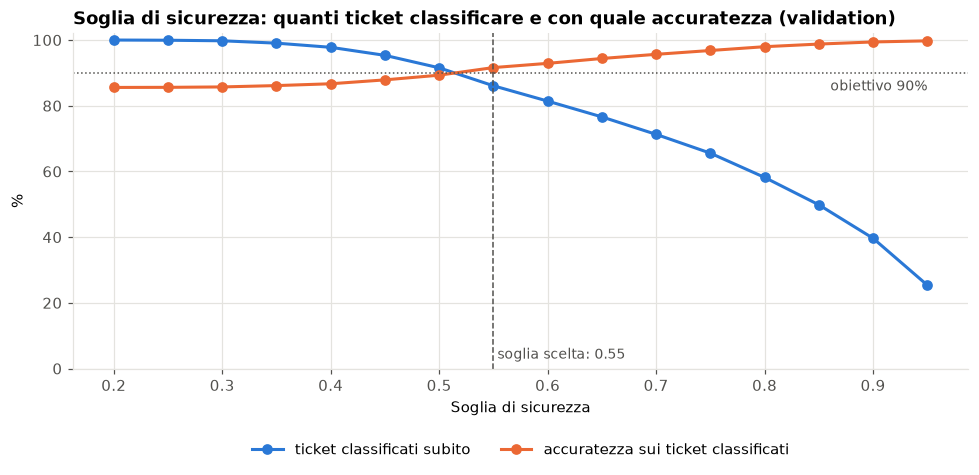

In [19]:
# Grafico: entrambe le curve sono percentuali quindi possono stare sullo stesso asse
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tabella_soglie.index, tabella_soglie["classificati subito (%)"], marker="o", color=COLORE, linewidth=2, label="ticket classificati subito")
ax.plot(tabella_soglie.index, tabella_soglie["accuratezza su questi (%)"], marker="o", color=COLORE_2, linewidth=2, label="accuratezza sui ticket classificati")
ax.axhline(ACCURATEZZA_OBIETTIVO * 100, color=TESTO_SECONDARIO, linestyle=":", linewidth=1)
ax.text(tabella_soglie.index.max(), ACCURATEZZA_OBIETTIVO * 100 - 2, f"obiettivo {ACCURATEZZA_OBIETTIVO:.0%}", ha="right", va="top", fontsize=9, color=TESTO_SECONDARIO)
ax.axvline(SOGLIA, color=TESTO_SECONDARIO, linestyle="--", linewidth=1)
ax.text(SOGLIA, 3, f" soglia scelta: {SOGLIA}", fontsize=9, color=TESTO_SECONDARIO)
ax.set_ylim(0, 102)
ax.set_title("Soglia di sicurezza: quanti ticket classificare e con quale accuratezza (validation)")
ax.set_xlabel("Soglia di sicurezza")
ax.set_ylabel("%")
# Legenda sotto il grafico così non copre le curve e le etichette
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()
plt.show()

In [20]:
# Verifica sul test: come si comporta con ticket mai visti
sicurezza_test = prob_test.max(axis=1)
corretto_test = pred_test == y_test_nomi
sopra_test = sicurezza_test >= SOGLIA

print(f"  ticket classificati subito: {sopra_test.mean() * 100:.1f}%")
print(f"  accuratezza su questi:      {corretto_test[sopra_test].mean() * 100:.1f}%")
print(f"  ticket con richiesta di dettagli: {(~sopra_test).mean() * 100:.1f}% "
      f"(accuratezza che avrebbero avuto: {corretto_test[~sopra_test].mean() * 100:.1f}%)")

  ticket classificati subito: 87.1%
  accuratezza su questi:      91.0%
  ticket con richiesta di dettagli: 12.9% (accuratezza che avrebbero avuto: 52.6%)


### Osservazioni (parte 10)
- **Soglia scelta: 0,55**, la più bassa che raggiunge l'obiettivo del 90% sulla validation: l'86,1% dei ticket viene classificato subito con accuratezza 91,6%; al 13,9% degli utenti il chatbot chiede più dettagli. Con 0,50 l'accuratezza si fermava all'89,3%.
- Senza soglia l'accuratezza è 85,6%: la soglia guadagna 6 punti chiedendo dettagli a circa 1 utente su 7.
- **Oltre 0,55 il compromesso diventa costoso:** ogni passo di 0,05 toglie circa 5 punti di ticket classificati subito per guadagnare solo 1-1,5 punti di accuratezza (con 0,70: 71,3% classificati, 95,6% di accuratezza).
- **Sul test la soglia regge:** 87,1% di ticket classificati subito con accuratezza 91,0% (obiettivo rispettato) e 12,9% di richieste di dettagli, valori molto vicini alla validation.
- **I ticket sotto soglia avrebbero avuto un'accuratezza del 52,6%**, chiedere dettagli è la scelta giusta. Con il 12,9% di richieste il chatbot intercetta il 44% di tutti gli errori del modello (6,1 punti su 14,0).
- Il 90% è una scelta di progetto: la soglia viene salvata nel file di configurazione e nell'app si può cambiare senza riaddestrare il modello.

## 11. Salvataggio

In [21]:
configurazione = {
    "modello_finale": MODELLO_FINALE,
    "soglia_sicurezza": SOGLIA,
    "accuratezza_obiettivo": ACCURATEZZA_OBIETTIVO,
    "classi": CLASSI,
    "risultati": {
        "f1_macro_validation_svm": round(float(f1_svm), 4),
        "f1_macro_validation_lstm": round(float(f1_lstm), 4),
        "f1_macro_test": round(float(f1_test), 4),
        "accuratezza_test": round(float(accuratezza_test), 4),        
    },
}

if MODELLO_FINALE == "SVM":
    configurazione["file_modello"] = "modello_classico_migliore.joblib"
else:
    # Modello completo: testo pulito -> vocabolario -> rete -> probabilità
    modello_completo = keras.Sequential([
        keras.Input(shape=(1,), dtype="string"),
        vettorizzatore,
        modello_lstm,
    ])
    modello_completo.save(MODELS_DIR / "modello_lstm.keras")
    configurazione["file_modello"] = "modello_lstm.keras"
    configurazione["max_len"] = MAX_LEN

with open(MODELS_DIR / "configurazione_modello.json", "w", encoding="utf-8") as f:
    json.dump(configurazione, f, indent=2, ensure_ascii=False)

storico.to_csv(MODELS_DIR / "storico_lstm.csv")
print(json.dumps(configurazione, indent=2, ensure_ascii=False))

{
  "modello_finale": "SVM",
  "soglia_sicurezza": 0.55,
  "accuratezza_obiettivo": 0.9,
  "classi": [
    "Access",
    "Administrative rights",
    "HR Support",
    "Hardware",
    "Internal Project",
    "Miscellaneous",
    "Purchase",
    "Storage"
  ],
  "risultati": {
    "f1_macro_validation_svm": 0.8554,
    "f1_macro_validation_lstm": 0.8348,
    "f1_macro_test": 0.8633,
    "accuratezza_test": 0.8601
  },
  "file_modello": "modello_classico_migliore.joblib"
}


In [22]:
# Controllo finale: richiamiamo il modello come farà l'app e classifichiamo un ticket di prova
with open(MODELS_DIR / "configurazione_modello.json", encoding="utf-8") as f:
    config = json.load(f)

esempio = ["hello my laptop screen is broken and the monitor cable does not connect thank you"]
if config["modello_finale"] == "SVM":
    modello_app = joblib.load(MODELS_DIR / config["file_modello"])
    probabilita = modello_app.predict_proba(esempio)[0]
    classi = modello_app.classes_
else:
    modello_app = keras.models.load_model(MODELS_DIR / config["file_modello"])
    # Il modello completo riceve testo: lo passiamo come tensore di stringhe di TensorFlow
    probabilita = modello_app.predict(tf.constant([[pulisci(esempio[0])]]), verbose=0)[0]
    classi = np.array(config["classi"])

print("Categoria prevista:", classi[probabilita.argmax()], f"(sicurezza {probabilita.max():.2f})")
print("Sopra la soglia?", probabilita.max() >= config["soglia_sicurezza"])

Categoria prevista: Hardware (sicurezza 0.99)
Sopra la soglia? True


### Osservazioni (parte 11)
- Salvato `configurazione_modello.json`: modello finale (SVM), soglia 0,55, obiettivo 90%, le 8 categorie e i risultati finali. Insieme a `modello_classico_migliore.joblib` è tutto ciò che serve all'app.
- Il file del modello è la pipeline completa (TF-IDF con la lista del rumore email -> SVM -> calibrazione): l'app gli passa il testo direttamente, senza ricostruire nulla.
- La LSTM non viene salvata perché non è stata scelta: il notebook la riaddestra con gli stessi risultati. Salvo comunque `storico_lstm.csv` per le curve di addestramento nella relazione.
- **Controllo finale:** ricaricato come farà l'app, il modello classifica il ticket di prova ("my laptop screen is broken and the monitor cable does not connect") come **Hardware con sicurezza 0,99**, sopra la soglia. Il ticket è in inglese come i dati di addestramento: nell'app il messaggio dell'utente, scritto in italiano, verrà prima tradotto dall'LLM.
- Il file `.joblib` va ricaricato con la stessa versione di scikit-learn: la fisserò in `requirements.txt`.

## 12. Riepilogo

| Aspetto | Valore / osservazione |
|---|---|
| `MAX_TOKENS` / `MAX_LEN` / ticket tagliati | **8.575** (8.573 parole presenti almeno 2 volte + padding e [UNK]) / **120** parole (95° percentile dei testi senza rumore email) / **4,4%** |
| Epoche di addestramento / epoca migliore / tempo per epoca | **4** (early stopping) / **2** (loss validazione interna 0,4976, accuratezza 83,4%) / 84-109 s su CPU |
| Segni di overfitting | Sì, rapidi: il train sale (accuratezza 71,8% -> 90,8%, loss 0,80 -> 0,19) mentre la validazione interna resta all'82,5-83,4% e la sua loss risale dopo l'epoca 2 (0,498 -> 0,541). Causa: 1,2 milioni di parametri, quasi tutti nell'Embedding imparato da zero |
| F1 macro sulla validation: SVM / LSTM | **0,8554 / 0,8348** (−0,0205) |
| Categorie in cui la LSTM fa meglio / peggio | Meglio solo in Purchase (+0,005, trascurabile). Peggio soprattutto in Administrative rights (−0,048), Hardware (−0,038) e Storage (−0,026) |
| Dimensione: SVM / LSTM | 14,1 / 14,4 MB. La LSTM richiede TensorFlow anche nell'app |
| Modello finale e motivazione | **SVM lineare con bigrammi, calibrata**: la regola fissata prima del test (LSTM scelta solo con almeno +0,01) la conferma con ampio margine; in più è più veloce, più leggera da pubblicare e interpretabile |
| **F1 macro e accuratezza sul test** | **0,8633 / 0,8601** |
| Validation -> test: differenza | **+0,008** (0,8554 -> 0,8633): nessun adattamento alla validation; stesso ordine delle categorie dalla migliore alla peggiore |
| Confusione principale (test) | Quando è incerto il modello risponde Hardware: Administrative rights 22%, Miscellaneous 11%, HR Support 9% finiscono lì |
| Effetto della calibrazione | F1 macro invariato (0,855 sulla validation), ma precision macro 0,848 -> 0,874 e recall macro 0,864 -> 0,839: le categorie piccole diventano più precise, Hardware riceve più ticket incerti |
| Soglia di sicurezza scelta | **0,55** (la più bassa con accuratezza ≥ 90% sulla validation: 86,1% di ticket classificati subito, accuratezza 91,6%) |
| Sul test: ticket classificati subito / accuratezza | **87,1% / 91,0%**; al 12,9% degli utenti il chatbot chiede dettagli (su quei ticket l'accuratezza sarebbe stata 52,6%): intercettato il 44% degli errori |